# RIAWELC Weld Defect Pipeline
## Data Preparation, Known-Weld Partitioning and YOLO Defect Localisation

**Pipeline:** radiographic weld image → **YOLO defect detection → ROI cropping** → ResNet50 / EfficientNet-B3 / ConvNeXt-Tiny → defect classification

**Classes:** Lack of Penetration (LP), Crack (CR), Porosity (PO), No Defect (ND)

## 1. Environment Setup

### 1.1 Install Dependencies

In [17]:
!pip -q install ultralytics scipy

### 1.2 Import Libraries

In [18]:
import os, re, json, math, time, random, hashlib, shutil, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from sklearn.model_selection import StratifiedGroupKFold
import torch

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

### 1.3 Experiment Configuration

`PROTOCOL` selects the evaluation setting:

| Value | Meaning |
|---|---|
| `"weld_holdout"` | Primary protocol. Train, validation and test welds are disjoint (methodology requirement 1). |
| `"known_weld"` | Secondary protocol. Official RIAWELC split after duplicate removal; test patches come from welds and radiographs seen in training. |

In [19]:
DATA_ROOT   = Path(r"C:\Users\dipkh\Downloads\RIAWELC-main(24k images)\RIAWELC-main\Dataset_partitioned")
PROJECT_DIR = Path(r"C:\Users\dipkh\Downloads\RIAWLC\3")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
OUTPUT_ROOT = PROJECT_DIR / "riawelc_outputs"
PROTOCOL    = "known_weld"

CLASS_ORDER   = ["Difetto4", "Difetto1", "Difetto2", "NoDifetto"]
DISPLAY_NAMES = {"Difetto4": "Lack of Penetration", "Difetto1": "Crack", "Difetto2": "Porosity", "NoDifetto": "No Defect"}
SHORT_NAMES   = {"Difetto4": "LP", "Difetto1": "CR", "Difetto2": "PO", "NoDifetto": "ND"}

TEST_FRAC, VAL_FRAC = 0.15, 0.15
SEED = 42

MANUAL_LABEL_DIR = None
PB_SE, PB_K, PB_MIN_CONTRAST, PB_MIN_AREA, PB_MAX_BOXES, PB_JOIN, PB_REL = 61, 2.5, 0.15, 80, 4, 3, 0.3

YOLO_MODEL    = "yolov8n.pt"
YOLO_EPOCHS   = 40
YOLO_IMGSZ    = 224
YOLO_BATCH    = 32
YOLO_PATIENCE = 15
YOLO_CONF     = 0.25
YOLO_WORKERS  = 0 if os.name == "nt" else 4
REUSE_YOLO    = False

CROP_PAD = 0.25
CROP_MIN = 160

assert PROTOCOL in {"weld_holdout", "known_weld"}
assert DATA_ROOT.exists(), f"DATA_ROOT not found: {DATA_ROOT}"
PROTO_DIR = OUTPUT_ROOT / PROTOCOL
SHARED    = PROTO_DIR / "_shared"
FIG_DIR   = SHARED / "figures"
for d in [SHARED, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)
NUM_CLASSES = len(CLASS_ORDER)
LABEL2ID = {c: i for i, c in enumerate(CLASS_ORDER)}
NAMES = [DISPLAY_NAMES[c] for c in CLASS_ORDER]
random.seed(SEED); np.random.seed(SEED)
print(f"Protocol: {PROTOCOL} | output: {PROTO_DIR.resolve()} | CUDA: {torch.cuda.is_available()}")

Protocol: known_weld | output: C:\Users\dipkh\Downloads\RIAWLC\3\riawelc_outputs\known_weld | CUDA: True


## 2. Dataset Indexing

### 2.1 Build the Image Index

In [20]:
SPLIT_ALIASES = {"training": "train", "train": "train", "validation": "val", "val": "val", "testing": "test", "test": "test"}
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def parse_ids(fname):
    base = Path(fname).stem.split("_[")[0]
    m = re.match(r"^(.*?)_Img(\d+)", base)
    if m:
        return m.group(1), f"{m.group(1)}_Img{m.group(2)}"
    return base.split("_")[0], base

rows, empty_dirs = [], []
for dirpath, dirnames, filenames in os.walk(DATA_ROOT):
    imgs = [f for f in filenames if Path(f).suffix.lower() in IMG_EXT]
    rel = Path(dirpath).relative_to(DATA_ROOT).parts
    if not imgs and not dirnames:
        empty_dirs.append("/".join(rel))
    for f in imgs:
        split = next((SPLIT_ALIASES[x.lower()] for x in rel if x.lower() in SPLIT_ALIASES), None)
        weld, radiograph = parse_ids(f)
        rows.append(dict(path=str(Path(dirpath) / f), file=f, official_split=split, cls=Path(dirpath).name,
                         weld=weld, radiograph=radiograph))
df_all = pd.DataFrame(rows)
assert len(df_all), f"No images found under {DATA_ROOT}"
df_all = df_all[df_all.cls.isin(CLASS_ORDER)].sort_values("path").reset_index(drop=True)
df_all["label"] = df_all.cls.map(LABEL2ID)
df_all["class_name"] = df_all.cls.map(DISPLAY_NAMES)
df_all["source"] = df_all.weld.str.extract(r"^([A-Za-z]+)", expand=False).fillna("other")
print(f"Files: {len(df_all):,} | welds: {df_all.weld.nunique()} | radiographs: {df_all.radiograph.nunique()} "
      f"| empty leaf folders: {len(empty_dirs)}")

Files: 244,102 | welds: 29 | radiographs: 109 | empty leaf folders: 108


### 2.2 Class and Official-Split Distribution

In [21]:
display(pd.crosstab(df_all.official_split, df_all.class_name, margins=True))

class_name,Crack,Lack of Penetration,No Defect,Porosity,All
official_split,,,,,
test,765,892,1200,752,3609
train,21202,31492,52200,32097,136991
val,29281,19780,28197,26244,103502
All,51248,52164,81597,59093,244102


### 2.3 Representative Samples per Class

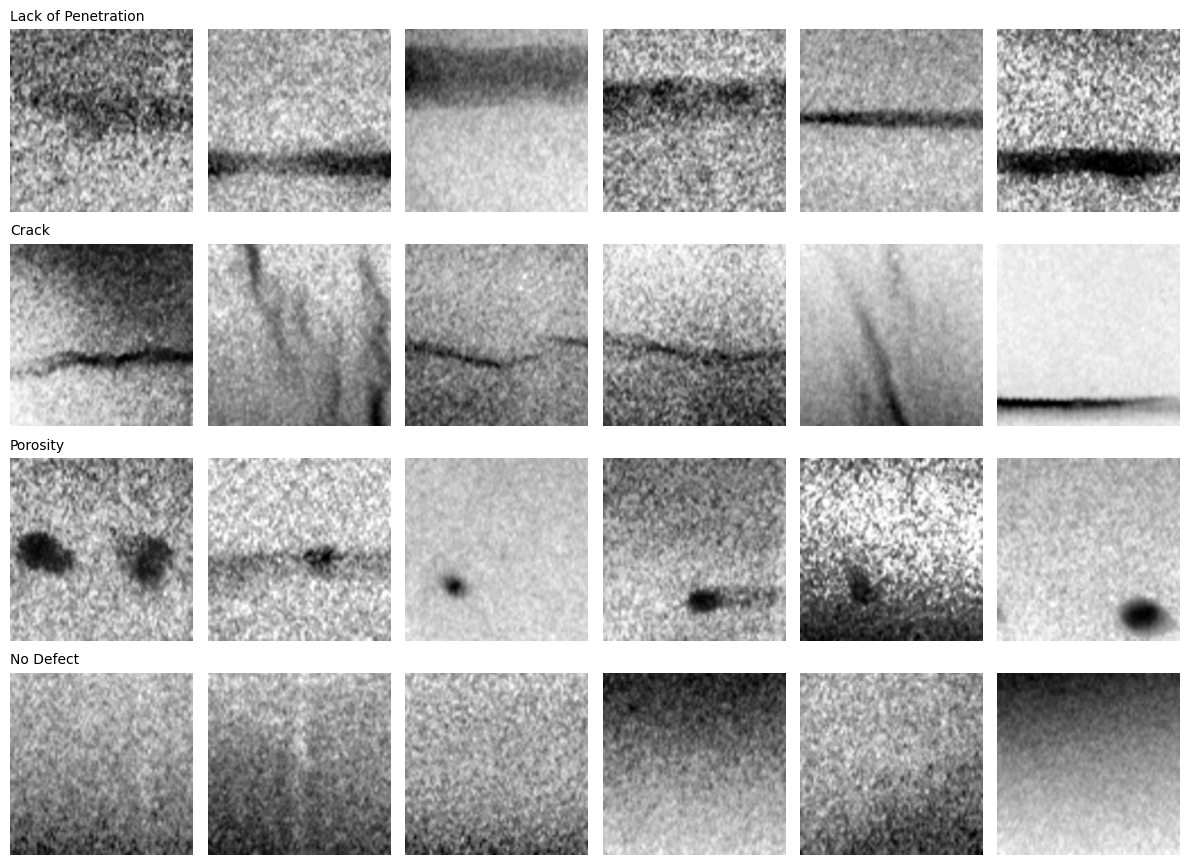

In [22]:
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(12, 2.2 * NUM_CLASSES))
for r, c in enumerate(CLASS_ORDER):
    sub = df_all[df_all.cls == c].sample(min(6, (df_all.cls == c).sum()), random_state=SEED)
    for k in range(6):
        ax = axes[r, k]; ax.axis("off")
        if k < len(sub):
            ax.imshow(Image.open(sub.path.iloc[k]).convert("L"), cmap="gray")
        if k == 0:
            ax.set_title(DISPLAY_NAMES[c], loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG_DIR / "class_samples.png", dpi=150); plt.show()

## 3. Data Integrity Audit

### 3.1 Exact-Duplicate Detection

In [23]:
def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

cache_file = OUTPUT_ROOT / "md5_cache.csv"
cache = pd.read_csv(cache_file).set_index("path").md5.to_dict() if cache_file.exists() else {}
df_all["md5"] = [cache.get(p) or md5(p) for p in df_all.path]
pd.concat([pd.DataFrame({"path": list(cache), "md5": list(cache.values())}), df_all[["path", "md5"]]]) \
  .drop_duplicates("path", keep="last").to_csv(cache_file, index=False)

test_h, train_h, val_h = (set(df_all.loc[df_all.official_split == s, "md5"]) for s in ["test", "train", "val"])
display(pd.DataFrame({
    "check": ["Files indexed", "Unique images (MD5)", "Official test images with a copy in official train",
              "Official test images with a copy in official val", "Official val images with a copy in official train"],
    "count": [len(df_all), df_all.md5.nunique(), len(test_h & train_h), len(test_h & val_h), len(val_h & train_h)]}))

,check,count
0,Files indexed,244102
1,Unique images (MD5),21965
2,Official test images with a copy in official t...,2444
3,Official test images with a copy in official val,1
4,Official val images with a copy in official train,1


### 3.2 Duplicate Removal

In [24]:
conflict = df_all.groupby("md5").label.nunique()
conflict = set(conflict[conflict > 1].index)
priority = {"test": 0, "val": 1, "train": 2}
df = (df_all[~df_all.md5.isin(conflict)]
      .assign(_p=lambda d: d.official_split.map(priority))
      .sort_values(["_p", "path"]).drop_duplicates("md5").drop(columns="_p")
      .sort_values("path").reset_index(drop=True))
print(f"Label-conflicting hashes removed: {len(conflict)} | unique images kept: {len(df):,} of {len(df_all):,} files")
display(pd.crosstab(df.official_split, df.class_name, margins=True))

Label-conflicting hashes removed: 1 | unique images kept: 21,964 of 244,102 files


class_name,Crack,Lack of Penetration,No Defect,Porosity,All
official_split,,,,,
test,765,446,600,632,2443
train,4197,2447,3300,3476,13420
val,1908,1113,1500,1580,6101
All,6870,4006,5400,5688,21964


## 4. Data Partitioning

### 4.1 Train / Validation / Test Split

In [25]:
def _sgkf_once(frame, frac, seed):
    k = max(2, round(1 / frac))
    a, b = next(StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
                .split(frame, frame.label.values, frame.weld.values))
    return frame.iloc[a], frame.iloc[b]

def weld_split(frame, n_trials=100):
    target = frame.label.value_counts(normalize=True).sort_index()
    best, best_score = None, np.inf
    for s in range(n_trials):
        trval, te = _sgkf_once(frame, TEST_FRAC, SEED + s)
        tr, va = _sgkf_once(trval, VAL_FRAC / (1 - TEST_FRAC), SEED + 1000 + s)
        parts = [tr, va, te]
        if any(p.label.nunique() < NUM_CLASSES for p in parts):
            continue
        dev = sum(np.abs(p.label.value_counts(normalize=True).reindex(target.index, fill_value=0) - target).max() for p in parts)
        size = abs(len(te) / len(frame) - TEST_FRAC) + abs(len(va) / len(frame) - VAL_FRAC)
        if dev + size < best_score:
            best, best_score = parts, dev + size
    return best

if PROTOCOL == "known_weld":
    df["split"] = df.official_split
else:
    tr, va, te = weld_split(df)
    df["split"] = "train"
    df.loc[va.index, "split"] = "val"
    df.loc[te.index, "split"] = "test"

display(pd.crosstab(df.split, df.class_name, margins=True).reindex(["train", "val", "test", "All"]))
for s in ["train", "val", "test"]:
    print(f"{s:>5} welds ({df.loc[df.split == s, 'weld'].nunique()}): {sorted(df.loc[df.split == s, 'weld'].unique())}")

class_name,Crack,Lack of Penetration,No Defect,Porosity,All
split,,,,,
train,4197,2447,3300,3476,13420
val,1908,1113,1500,1580,6101
test,765,446,600,632,2443
All,6870,4006,5400,5688,21964


train welds (29): ['RRT-09R', 'RRT-101R', 'RRT-102R', 'RRT-105R', 'RRT-107R', 'RRT-11R', 'RRT-12R', 'RRT-13R', 'RRT-15R', 'RRT-20R', 'RRT-22R', 'RRT-23R', 'RRT-24R', 'RRT-26R', 'RRT-27R', 'RRT-28R', 'RRT-29R', 'RRT-30R', 'RRT-31R', 'RRT-39R', 'RRT-40R', 'RRT-42R', 'RRT-88R', 'RRT-90R', 'RRT-94R', 'RRT-97R', 'RRT-98R', 'RRT-99R', 'bam5']
  val welds (27): ['RRT-101R', 'RRT-102R', 'RRT-105R', 'RRT-107R', 'RRT-12R', 'RRT-13R', 'RRT-15R', 'RRT-20R', 'RRT-22R', 'RRT-23R', 'RRT-24R', 'RRT-26R', 'RRT-27R', 'RRT-28R', 'RRT-29R', 'RRT-30R', 'RRT-31R', 'RRT-39R', 'RRT-40R', 'RRT-42R', 'RRT-88R', 'RRT-90R', 'RRT-94R', 'RRT-97R', 'RRT-98R', 'RRT-99R', 'bam5']
 test welds (28): ['RRT-09R', 'RRT-101R', 'RRT-102R', 'RRT-105R', 'RRT-107R', 'RRT-12R', 'RRT-13R', 'RRT-15R', 'RRT-20R', 'RRT-22R', 'RRT-23R', 'RRT-24R', 'RRT-26R', 'RRT-27R', 'RRT-28R', 'RRT-29R', 'RRT-30R', 'RRT-31R', 'RRT-39R', 'RRT-40R', 'RRT-42R', 'RRT-88R', 'RRT-90R', 'RRT-94R', 'RRT-97R', 'RRT-98R', 'RRT-99R', 'bam5']


### 4.2 Leakage Verification

In [26]:
def overlap(level, a, b):
    return len(set(df.loc[df.split == a, level]) & set(df.loc[df.split == b, level]))

leak = pd.DataFrame([{"level": lvl, "train ∩ test": overlap(lvl, "train", "test"),
                      "train ∩ val": overlap(lvl, "train", "val"), "val ∩ test": overlap(lvl, "val", "test")}
                     for lvl in ["md5", "radiograph", "weld"]])
display(leak)
assert leak.loc[leak.level == "md5", ["train ∩ test", "train ∩ val", "val ∩ test"]].values.sum() == 0
if PROTOCOL == "weld_holdout":
    assert leak[["train ∩ test", "train ∩ val", "val ∩ test"]].values.sum() == 0
    print("Verified: no image, radiograph or weld is shared between train, validation and test.")
else:
    print("Known-weld protocol: images are unique per split; welds and radiographs are shared by design.")

,level,train ∩ test,train ∩ val,val ∩ test
0,md5,0,0,0
1,radiograph,108,107,107
2,weld,28,27,27


Known-weld protocol: images are unique per split; welds and radiographs are shared by design.


## 5. Bounding-Box Annotation for YOLO

RIAWELC provides class labels only. Boxes are produced by an unsupervised, label-free intensity-anomaly localiser (morphological black-hat on the contrast-normalised patch), applied only to defect images of the training and validation partitions. No-defect images are used as background. If manual YOLO annotations are available, set `MANUAL_LABEL_DIR` and they replace the automatic boxes.

### 5.1 Weak Box Generator

In [27]:
def pseudo_boxes(img):
    a = np.asarray(img.convert("L"), dtype=np.float32)
    lo, hi = np.percentile(a, [1, 99])
    a = np.clip((a - lo) / max(hi - lo, 1.0), 0, 1)
    sm = ndi.gaussian_filter(a, 2.5)
    small = ndi.zoom(sm, 0.5, order=1)
    bg = ndi.grey_closing(small, size=(PB_SE, PB_SE))
    bg = ndi.zoom(ndi.gaussian_filter(bg, 3), (a.shape[0] / small.shape[0], a.shape[1] / small.shape[1]), order=1)
    res = np.clip(bg - sm, 0, None)
    thr = max(res.mean() + PB_K * res.std(), PB_MIN_CONTRAST)
    m = ndi.binary_dilation(ndi.binary_opening(res > thr, iterations=1), iterations=PB_JOIN)
    lab, n = ndi.label(m)
    if n == 0:
        return []
    idx = np.arange(1, n + 1)
    areas, score = ndi.sum(m, lab, idx), ndi.sum(res, lab, idx)
    objs = ndi.find_objects(lab)
    keep = [i for i in np.argsort(score)[::-1]
            if areas[i] >= PB_MIN_AREA and score[i] >= PB_REL * score.max()][:PB_MAX_BOXES]
    return [(objs[i][1].start, objs[i][0].start, objs[i][1].stop, objs[i][0].stop) for i in keep]

def read_manual_boxes(row):
    f = Path(MANUAL_LABEL_DIR) / (Path(row.file).stem + ".txt")
    if not f.exists():
        return None
    W, H = Image.open(row.path).size
    out = []
    for line in f.read_text().split("\n"):
        p = line.split()
        if len(p) == 5:
            cx, cy, w, h = map(float, p[1:])
            out.append((int((cx - w / 2) * W), int((cy - h / 2) * H), int((cx + w / 2) * W), int((cy + h / 2) * H)))
    return out

### 5.2 Annotate Training and Validation Images

In [28]:
ann_df = df[df.split.isin(["train", "val"])]
boxes = {}
t0 = time.time()
for i, r in ann_df.iterrows():
    if r.cls == "NoDifetto":
        boxes[i] = []
    elif MANUAL_LABEL_DIR:
        b = read_manual_boxes(r)
        if b is not None:
            boxes[i] = b
    else:
        boxes[i] = pseudo_boxes(Image.open(r.path))
ann_df = ann_df.assign(n_boxes=[len(boxes[i]) if i in boxes else -1 for i in ann_df.index])
print(f"Annotated {len(boxes):,} images in {time.time() - t0:.0f}s "
      f"({'manual labels' if MANUAL_LABEL_DIR else 'automatic weak boxes'})")
summary = ann_df[ann_df.cls != "NoDifetto"].groupby(["split", "class_name"]).n_boxes.agg(
    images="size", with_box=lambda s: int((s > 0).sum()), mean_boxes=lambda s: s[s > 0].mean())
display(summary.round(2))

Annotated 19,521 images in 211s (automatic weak boxes)


images  with_box  mean_boxes
split class_name                                       
train Crack                  4197      3934        1.59
      Lack of Penetration    2447      2321        1.88
      Porosity               3476      3403        1.36
val   Crack                  1908      1795        1.57
      Lack of Penetration    1113      1064        1.86
      Porosity               1580      1539        1.37

### 5.3 Annotation Quality Check

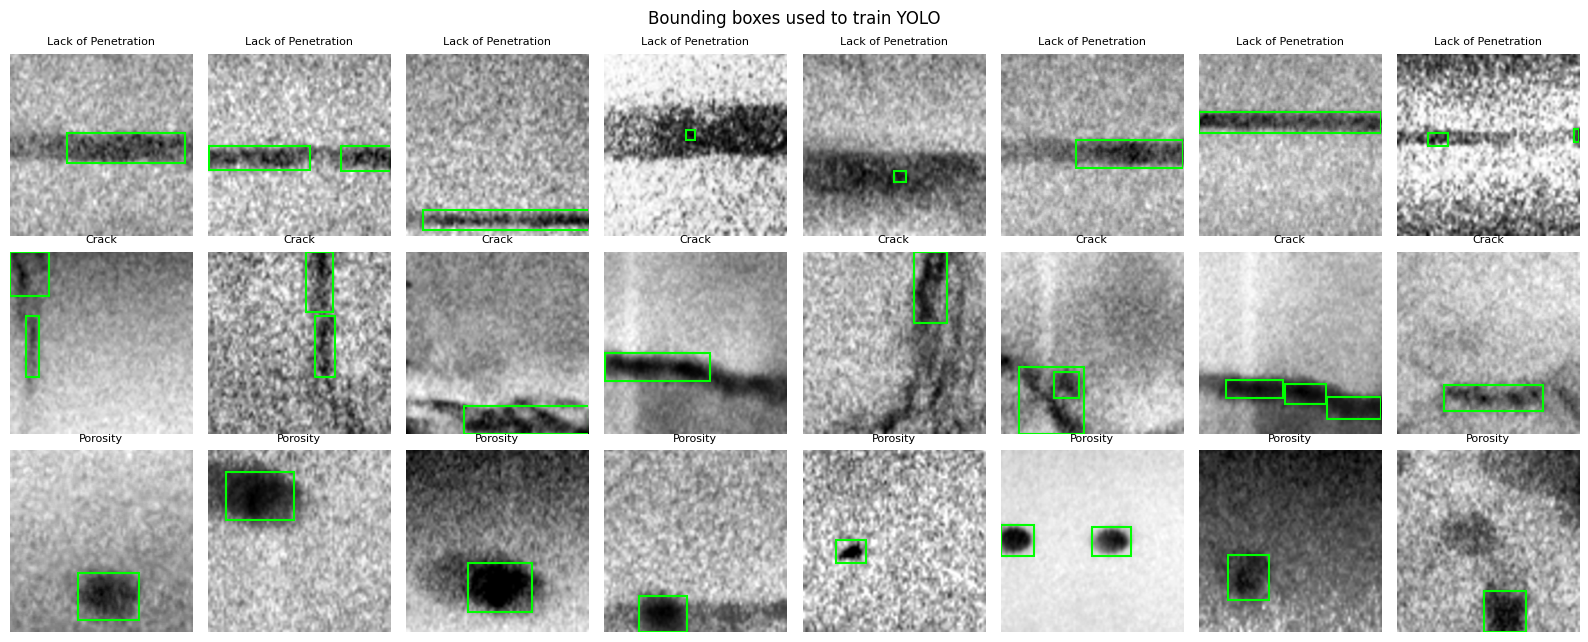

In [29]:
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
pick = pd.concat([ann_df[(ann_df.cls == c) & (ann_df.n_boxes > 0)].sample(8, random_state=SEED)
                  for c in CLASS_ORDER if c != "NoDifetto"])
for ax, (i, r) in zip(axes.ravel(), pick.iterrows()):
    ax.imshow(Image.open(r.path).convert("L"), cmap="gray"); ax.axis("off")
    for x0, y0, x1, y1 in boxes[i]:
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=1.5))
    ax.set_title(r.class_name, fontsize=8)
plt.suptitle("Bounding boxes used to train YOLO"); plt.tight_layout()
plt.savefig(FIG_DIR / "yolo_training_boxes.png", dpi=150); plt.show()

## 6. YOLO Detector Training

### 6.1 Build the YOLO Dataset

In [30]:
YOLO_DIR = SHARED / "yolo_dataset"
if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)
counts = Counter()
for i, b in boxes.items():
    r = df.loc[i]
    if r.cls != "NoDifetto" and len(b) == 0:
        continue
    img_p = YOLO_DIR / "images" / r.split / f"{i:06d}.png"
    lab_p = YOLO_DIR / "labels" / r.split / f"{i:06d}.txt"
    img_p.parent.mkdir(parents=True, exist_ok=True); lab_p.parent.mkdir(parents=True, exist_ok=True)
    im = Image.open(r.path).convert("L"); W, H = im.size
    im.save(img_p)
    lab_p.write_text("\n".join(f"0 {(x0 + x1) / 2 / W:.6f} {(y0 + y1) / 2 / H:.6f} {(x1 - x0) / W:.6f} {(y1 - y0) / H:.6f}"
                               for x0, y0, x1, y1 in b))
    counts[(r.split, "background" if r.cls == "NoDifetto" else "defect")] += 1
yaml_path = YOLO_DIR / "data.yaml"
yaml_path.write_text(f"path: {YOLO_DIR.resolve().as_posix()}\ntrain: images/train\nval: images/val\nnames:\n  0: defect\n")
display(pd.Series(counts).unstack().fillna(0).astype(int))

,background,defect
train,3300,9658
val,1500,4398


### 6.2 Train YOLO

In [31]:
from ultralytics import YOLO
RUN_DIR = SHARED.resolve() / "yolo_run"
best_pt = RUN_DIR / "weights" / "best.pt"
legacy_run = PROJECT_DIR / "runs" / "detect" / "riawelc_outputs" / PROTOCOL / "_shared" / "yolo_run"
if not best_pt.exists() and (legacy_run / "weights" / "best.pt").exists():
    shutil.copytree(legacy_run, RUN_DIR, dirs_exist_ok=True)
    print("Recovered the trained detector from", legacy_run.resolve())
if not (REUSE_YOLO and best_pt.exists()):
    yolo = YOLO(YOLO_MODEL)
    yolo.train(data=str(yaml_path.resolve()), imgsz=YOLO_IMGSZ, epochs=YOLO_EPOCHS, batch=YOLO_BATCH,
               patience=YOLO_PATIENCE, seed=SEED, workers=YOLO_WORKERS, project=str(SHARED.resolve()),
               name="yolo_run", exist_ok=True, fliplr=0.5, flipud=0.5, degrees=0.0, mosaic=0.5,
               hsv_h=0.0, hsv_s=0.0, hsv_v=0.3, plots=True, verbose=False)
    trained_dir = Path(yolo.trainer.save_dir).resolve()
    if trained_dir != RUN_DIR:
        shutil.copytree(trained_dir, RUN_DIR, dirs_exist_ok=True)
assert best_pt.exists(), f"Detector weights not found: {best_pt}"
detector = YOLO(str(best_pt))
print("Detector:", best_pt.resolve())

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.184  Python-3.10.11 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\dipkh\Downloads\RIAWLC\3\riawelc_outputs\known_weld\_shared\yolo_dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.3, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, l

### 6.3 Detector Validation Metrics

In [32]:
val_metrics = detector.val(data=str(yaml_path.resolve()), imgsz=YOLO_IMGSZ, split="val", workers=YOLO_WORKERS,
                           project=str(SHARED.resolve()), name="yolo_val", exist_ok=True, verbose=False)
yolo_metrics = {"precision": float(val_metrics.box.mp), "recall": float(val_metrics.box.mr),
                "mAP50": float(val_metrics.box.map50), "mAP50-95": float(val_metrics.box.map)}
display(pd.DataFrame([yolo_metrics], index=["YOLO (validation)"]).round(4))

Ultralytics 8.4.184  Python-3.10.11 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 79.7±38.6 MB/s, size: 17.8 KB)
val: Scanning C:\Users\dipkh\Downloads\RIAWLC\3\riawelc_outputs\known_weld\_shared\yolo_dataset\labels\val.cache... 5898 images, 1500 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5898/5898  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 369/369 4.3it/s 1:260.2sss
                   all       5898       6910      0.805      0.732       0.84      0.626
Speed: 0.2ms preprocess, 3.1ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to C:\Users\dipkh\Downloads\RIAWLC\3\riawelc_outputs\known_weld\_shared\yolo_val


,precision,recall,mAP50,mAP50-95
YOLO (validation),0.805,0.732,0.8398,0.6262


## 7. YOLO Inference and ROI Cropping

### 7.1 Detect and Crop All Images

In [33]:
CROP_DIR = SHARED / "roi_crops"
CROP_DIR.mkdir(exist_ok=True)

def roi_from_boxes(bxs, W, H):
    if not len(bxs):
        return (0, 0, W, H)
    x0, y0 = bxs[:, 0].min(), bxs[:, 1].min()
    x1, y1 = bxs[:, 2].max(), bxs[:, 3].max()
    pw, ph = (x1 - x0) * CROP_PAD, (y1 - y0) * CROP_PAD
    x0, y0, x1, y1 = x0 - pw, y0 - ph, x1 + pw, y1 + ph
    side_w, side_h = max(x1 - x0, CROP_MIN), max(y1 - y0, CROP_MIN)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    x0, x1 = np.clip([cx - side_w / 2, cx + side_w / 2], 0, W)
    y0, y1 = np.clip([cy - side_h / 2, cy + side_h / 2], 0, H)
    if x1 - x0 < min(CROP_MIN, W):
        x0, x1 = (0, min(CROP_MIN, W)) if x0 == 0 else (W - min(CROP_MIN, W), W)
    if y1 - y0 < min(CROP_MIN, H):
        y0, y1 = (0, min(CROP_MIN, H)) if y0 == 0 else (H - min(CROP_MIN, H), H)
    return tuple(int(round(v)) for v in (x0, y0, x1, y1))

det_rows, t0 = [], time.time()
paths = df.path.tolist()
for s in range(0, len(paths), 128):
    ims = [Image.open(p).convert("L") for p in paths[s:s + 128]]
    results = detector.predict([im.convert("RGB") for im in ims], imgsz=YOLO_IMGSZ, conf=YOLO_CONF, verbose=False)
    for j, (im, res) in enumerate(zip(ims, results)):
        i = s + j
        bxs = res.boxes.xyxy.cpu().numpy() if len(res.boxes) else np.zeros((0, 4))
        conf = float(res.boxes.conf.max()) if len(res.boxes) else 0.0
        roi = roi_from_boxes(bxs, *im.size)
        out = CROP_DIR / f"{i:06d}.png"
        im.crop(roi).save(out)
        det_rows.append(dict(cls_path=str(out), n_det=len(bxs), det_conf=conf,
                             roi_x0=roi[0], roi_y0=roi[1], roi_x1=roi[2], roi_y1=roi[3],
                             boxes=json.dumps(np.round(bxs, 1).tolist())))
    if s % 2560 == 0:
        print(f"{s + len(ims):,}/{len(paths):,} images | {time.time() - t0:.0f}s")
df = pd.concat([df.reset_index(drop=True), pd.DataFrame(det_rows)], axis=1)
df["has_detection"] = df.n_det > 0
print(f"Done in {time.time() - t0:.0f}s")

128/21,964 images | 3s
2,688/21,964 images | 43s
5,248/21,964 images | 82s
7,808/21,964 images | 121s
10,368/21,964 images | 158s
12,928/21,964 images | 197s
15,488/21,964 images | 239s
18,048/21,964 images | 281s
20,608/21,964 images | 321s
Done in 343s


### 7.2 Detection Rate by Partition and Class

In [34]:
rate = df.pivot_table(index="split", columns="class_name", values="has_detection", aggfunc="mean").reindex(["train", "val", "test"])
display((rate * 100).round(2).rename_axis(columns="detection rate (%)"))

detection rate (%),Crack,Lack of Penetration,No Defect,Porosity
split,,,,
train,87.68,85.00,0.70,96.78
val,87.89,85.98,1.00,96.39
test,87.84,84.30,1.17,96.99


### 7.3 Test-Set Detections and Cropped Regions

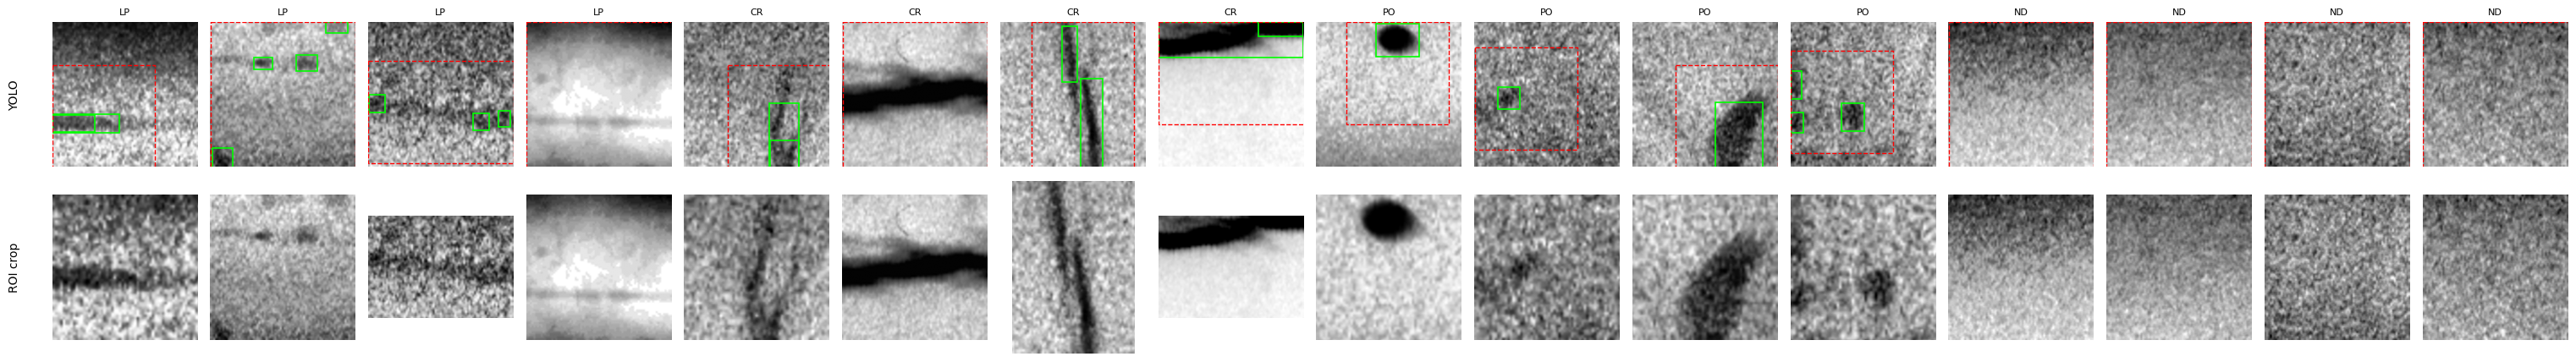

In [35]:
pick = pd.concat([df[(df.split == "test") & (df.cls == c)].sample(4, random_state=SEED) for c in CLASS_ORDER])
fig, axes = plt.subplots(2, len(pick), figsize=(1.9 * len(pick), 4.4))
for k, (_, r) in enumerate(pick.iterrows()):
    axes[0, k].imshow(Image.open(r.path).convert("L"), cmap="gray")
    for x0, y0, x1, y1 in json.loads(r.boxes):
        axes[0, k].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=1.2))
    axes[0, k].add_patch(plt.Rectangle((r.roi_x0, r.roi_y0), r.roi_x1 - r.roi_x0, r.roi_y1 - r.roi_y0,
                                       fill=False, ec="red", lw=1, ls="--"))
    axes[0, k].set_title(SHORT_NAMES[r.cls], fontsize=8)
    axes[1, k].imshow(Image.open(r.cls_path).convert("L"), cmap="gray")
    for a in axes[:, k]:
        a.axis("off")
axes[0, 0].text(-0.3, 0.5, "YOLO", transform=axes[0, 0].transAxes, rotation=90, va="center")
axes[1, 0].text(-0.3, 0.5, "ROI crop", transform=axes[1, 0].transAxes, rotation=90, va="center")
plt.tight_layout(); plt.savefig(FIG_DIR / "yolo_test_detections.png", dpi=150); plt.show()

## 8. Export Shared Manifest and Configuration

In [36]:
cols = ["path", "cls_path", "file", "cls", "class_name", "label", "split", "official_split", "weld", "radiograph",
        "source", "md5", "n_det", "det_conf", "has_detection", "roi_x0", "roi_y0", "roi_x1", "roi_y1", "boxes"]
df[cols].to_csv(SHARED / "manifest.csv", index=False)
config = dict(protocol=PROTOCOL, class_order=CLASS_ORDER, display_names=DISPLAY_NAMES, short_names=SHORT_NAMES,
              n_files=len(df_all), n_unique=len(df), split_counts=df.split.value_counts().to_dict(),
              test_welds=sorted(df.loc[df.split == "test", "weld"].unique()),
              annotation="manual" if MANUAL_LABEL_DIR else "automatic weak boxes",
              yolo_model=YOLO_MODEL, yolo_val_metrics=yolo_metrics, crop_pad=CROP_PAD, crop_min=CROP_MIN, seed=SEED)
(SHARED / "config.json").write_text(json.dumps(config, indent=2))
print("Manifest:", (SHARED / "manifest.csv").resolve())
print("Config:  ", (SHARED / "config.json").resolve())

Manifest: C:\Users\dipkh\Downloads\RIAWLC\3\riawelc_outputs\known_weld\_shared\manifest.csv
Config:   C:\Users\dipkh\Downloads\RIAWLC\3\riawelc_outputs\known_weld\_shared\config.json
